# Malaysian Federal Operating Expenditure: Benford's Law Test (1980–2025)
Data source: data.gov.my (Accountant-General's Department), CC BY 4.0.

Goal: explore how federal operating spending changed and test whether the figures follow Benford's Law, an audit screening technique.

## 1. Load the data

In [1]:
%pip install pandas
import pandas as pd

url = "https://storage.data.gov.my/publicadmin/federal_finance_year_oe.csv"
df = pd.read_csv(url)
print(df.shape)
df.head()

Note: you may need to restart the kernel to use updated packages.
(517, 3)


,date,object,value
0,1979-01-01,total,7890
1,1980-01-01,total,10292
2,1981-01-01,total,13686
3,1982-01-01,total,15922
4,1983-01-01,total,16124


## 2. Clean the data
Removed: "total" and "debt_service" rows (subtotals, to avoid double-counting), zero values and 1979 (debt service not split that year).

In [2]:
remove = ["total", "debt_service"]
clean = df[(~df["object"].isin(remove)) & (df["value"] > 0)].copy()
print("Before:", len(df), "| After:", len(clean))
df["object"].value_counts()

Before: 517 | After: 421


object
total                 47
emoluments            47
retirement_charges    47
debt_service          47
debt_service_dom      47
debt_service_ext      47
supplies_services     47
subsidies_sa          47
asset_acquisition     47
grants_transfers      47
other                 47
Name: count, dtype: int64

In [3]:
clean["date"] = pd.to_datetime(clean["date"])
clean["year"] = clean["date"].dt.year
clean.head()

,date,object,value,year
47,1979-01-01,emoluments,2370,1979
48,1980-01-01,emoluments,2854,1980
49,1981-01-01,emoluments,3600,1981
50,1982-01-01,emoluments,3928,1982
51,1983-01-01,emoluments,5666,1983


### Reconciliation check
Rebuilt yearly totals from the detailed rows and compared them with the official totals. All years from 1980 onwards agree within ±2 (RM mil), explained by rounding.

In [4]:
official = df[df["object"] == "total"].copy()
official["year"] = pd.to_datetime(official["date"]).dt.year
rebuilt = clean.groupby("year")["value"].sum()

check = official.set_index("year")["value"].to_frame("official_total")
check["rebuilt_total"] = rebuilt
check["difference"] = check["official_total"] - check["rebuilt_total"]
check

,official_total,rebuilt_total,difference
year,,,
1979,7890,6619,1271
1980,10292,10292,0
1981,13686,13686,0
1982,15922,15922,0
1983,16124,16124,0
1984,17506,17506,0
1985,18766,18766,0
1986,20075,20075,0
1987,20185,20185,0


In [5]:
df[df["date"].str.startswith("1979")]

,date,object,value
0,1979-01-01,total,7890
47,1979-01-01,emoluments,2370
94,1979-01-01,retirement_charges,338
141,1979-01-01,debt_service,1271
188,1979-01-01,debt_service_dom,0
235,1979-01-01,debt_service_ext,0
282,1979-01-01,supplies_services,1216
329,1979-01-01,subsidies_sa,165
376,1979-01-01,asset_acquisition,146
423,1979-01-01,grants_transfers,2186


In [6]:
clean = clean[clean["year"] !=1979].copy()
print("Rows now:", len(clean))

rebuilt = clean.groupby("year")["value"].sum()
check["rebuilt_total"] = rebuilt
check["difference"] = check["official_total"] - check["rebuilt_total"]
check["difference"].abs().max()

Rows now: 414


np.float64(2.0)

## 3. Explore with SQL

In [7]:
import sqlite3

conn = sqlite3.connect("federal_oe.db")
clean.to_sql("oe", conn, if_exists="replace", index=False)
print("Saved to table 'oe'")

Saved to table 'oe'


In [8]:
q1 = """
SELECT object,
        ROUND(SUM(value), 0) AS total_rm_mil
FROM oe
GROUP BY object
ORDER BY total_rm_mil DESC;
"""

pd.read_sql(q1, conn)

,object,total_rm_mil
0,emoluments,1652215.0
1,grants_transfers,885213.0
2,supplies_services,770421.0
3,subsidies_sa,742076.0
4,debt_service_dom,677820.0
5,retirement_charges,485877.0
6,other,52411.0
7,debt_service_ext,51670.0
8,asset_acquisition,44878.0


In [9]:
q2 = """
SELECT object,
       SUM(CASE WHEN year = 2000 THEN value END) AS y2000,
       SUM(CASE WHEN year = 2025 THEN value END) AS y2025,
       ROUND(SUM(CASE WHEN year = 2025 THEN value END) * 1.0/
             SUM(CASE WHEN year = 2000 THEN value END), 1) AS times_bigger
FROM oe
GROUP BY object
ORDER BY times_bigger DESC;
"""
pd.read_sql(q2, conn)

,object,y2000,y2025,times_bigger
0,subsidies_sa,4824,55268,11.5
1,retirement_charges,4187,38559,9.2
2,debt_service_dom,7868,53111,6.8
3,emoluments,16357,101451,6.2
4,supplies_services,7360,42174,5.7
5,grants_transfers,11757,37544,3.2
6,asset_acquisition,572,1281,2.2
7,debt_service_ext,1187,600,0.5
8,other,2435,788,0.3


In [10]:
clean[(clean["object"] == "retirement_charges") & (clean["year"].isin([2010, 2023]))]

,date,object,value,year
125,2010-01-01,retirement_charges,11515,2010
138,2023-01-01,retirement_charges,34080,2023


In [11]:
def first_digit(x):
    s = str(abs(x)).lstrip("0.")
    return int(s[0])

clean["first_digit"] = clean["value"].apply(first_digit)
clean[["value", "first_digit"]].head(10)

,value,first_digit
48,2854,2
49,3600,3
50,3928,3
51,5666,5
52,5848,5
53,6002,6
54,6454,6
55,6504,6
56,6872,6
57,7381,7


## 4. Benford's Law test
Benford's Law predicts about 30% of naturally occurring figures start with 1 and under 5% with 9. Auditors use it to spot figures that may have been manipulated.

In [12]:
import numpy as np

digits = range(1,10)
expected = [np.log10(1+1/d) for d in digits]
actual = clean["first_digit"].value_counts(normalize=True).reindex(digits, fill_value=0)

benford = pd.DataFrame({
    "digit": list(digits),
    "expected_pct": [round(e * 100, 1) for e in expected],
    "actual_pct": (actual.values * 100).round(1)
})
benford["gap"] = (benford["actual_pct"] - benford["expected_pct"]).round(1)
benford

,digit,expected_pct,actual_pct,gap
0,1,30.1,27.5,-2.6
1,2,17.6,18.6,1.0
2,3,12.5,14.3,1.8
3,4,9.7,7.5,-2.2
4,5,7.9,8.9,1.0
5,6,6.7,7.2,0.5
6,7,5.8,7.0,1.2
7,8,5.1,5.1,0.0
8,9,4.6,3.9,-0.7


In [13]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


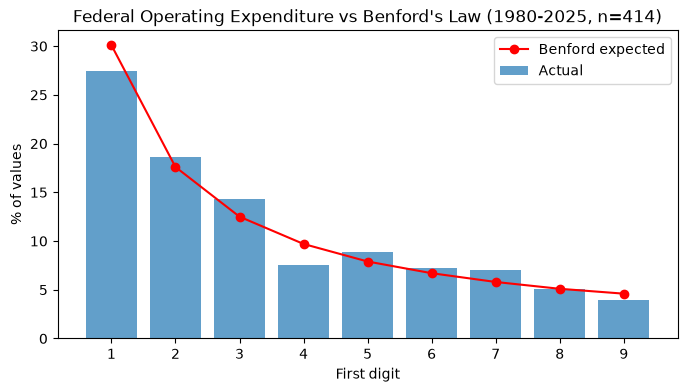

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,4))
plt.bar(benford["digit"], benford["actual_pct"], label="Actual", alpha=0.7)
plt.plot(benford["digit"], benford["expected_pct"], color="red", marker="o", label="Benford expected")
plt.xticks(list(digits))
plt.xlabel("First digit")
plt.ylabel("% of values")
plt.title("Federal Operating Expenditure vs Benford's Law (1980-2025, n=414)")
plt.legend()
plt.show()

In [15]:
mad = (benford["actual_pct"] - benford["expected_pct"]).abs().mean() / 100
print("MAD:", round(mad, 4))

MAD: 0.0122


## 5. Conclusion
The figures broadly follow Benford's Law (MAD = 0.0122, marginally acceptable under Nigrini's thresholds). No digit shows a suspicious spike.
Limitations: small sample (414 values) and annual category totals rather than individual transactions, so this is an illustrative test, not an audit finding.